In [ ]:
!pip install -q transformers datasets sentence-transformers accelerate evaluate matplotlib seaborn tqdm


In [ ]:
import torch
import numpy as np
import random
import matplotlib.pyplot as plt
import seaborn as sns


from datasets import load_dataset, Dataset
from transformers import (
    GPT2Tokenizer,
    GPT2LMHeadModel,
    Trainer,
    TrainingArguments,
    DataCollatorForLanguageModeling
)

from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)


Device: cpu


In [ ]:
dataset = load_dataset("ag_news", split="train")

print("Total samples:", len(dataset))
print(dataset[0])


Total samples: 120000
{'text': "Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2}


In [ ]:
authors = {}

for label in range(4):  # use 3 categories
    texts = [x["text"] for x in dataset if x["label"] == label]
    texts = [t for t in texts if 20 < len(t) <= 200]
    authors[f"author_{label}"] = texts[:300]

for k in authors:
    print(k, len(authors[k]))


author_0 300
author_1 300
author_2 300
author_3 300


In [ ]:
tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
tokenizer.pad_token = tokenizer.eos_token


In [ ]:
def build_dataset(texts):
    encodings = tokenizer(
        texts,
        truncation=True,
        padding="max_length",
        max_length=64
    )
    return Dataset.from_dict(encodings)


In [ ]:
import os
from google.colab import drive

drive.mount('/content/drive')

BASE_SAVE_DIR = "/content/drive/MyDrive/micro_style_models"
os.makedirs(BASE_SAVE_DIR, exist_ok=True)


def fine_tune_or_load(texts, author_name):

    save_path = os.path.join(BASE_SAVE_DIR, author_name)

    # ✅ If model already exists → LOAD
    if os.path.exists(save_path):
        print(f"Loading saved model for {author_name}")
        model = GPT2LMHeadModel.from_pretrained(save_path)
        model.to(device)
        return model

    # ✅ Otherwise → TRAIN
    print(f"Training new model for {author_name}")

    model = GPT2LMHeadModel.from_pretrained("gpt2")
    model.to(device)

    train_dataset = build_dataset(texts)

    data_collator = DataCollatorForLanguageModeling(
        tokenizer=tokenizer,
        mlm=False
    )

    training_args = TrainingArguments(
        output_dir="./temp_training",
        per_device_train_batch_size=8,
        num_train_epochs=2,
        save_strategy="no",
        logging_steps=100,
        learning_rate=5e-5,
        fp16=torch.cuda.is_available(),
        report_to="none"
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        data_collator=data_collator
    )

    trainer.train()

    # ✅ SAVE MODEL TO DRIVE
    model.save_pretrained(save_path)
    tokenizer.save_pretrained(save_path)

    print(f"Model saved for {author_name}")

    return model


Mounted at /content/drive


In [ ]:
DATA_SIZES = [25, 50, 100]
trained_models = {}

for author in authors:
    trained_models[author] = {}

    for size in DATA_SIZES:

        model_name = f"{author}_{size}"

        print(f"Processing {model_name}")

        trained_models[author][size] = fine_tune_or_load(
            authors[author][:size],
            model_name
        )


Processing author_0_25
Loading saved model for author_0_25


Processing author_0_50
Loading saved model for author_0_50


Processing author_0_100
Loading saved model for author_0_100


Processing author_1_25
Loading saved model for author_1_25


Processing author_1_50
Loading saved model for author_1_50


...

Processing author_2_50
Loading saved model for author_2_50


Processing author_2_100
Loading saved model for author_2_100


Processing author_3_25
Loading saved model for author_3_25


Processing author_3_50
Loading saved model for author_3_50


Processing author_3_100
Loading saved model for author_3_100


In [ ]:
def generate_text(model, prompt=""):
    if not prompt:
        # If prompt is empty, start generation with the EOS token (or BOS if defined)
        # GPT2 typically doesn't have a BOS token, so EOS token is often used as a start token for generation
        input_ids = torch.full((1, 1), tokenizer.eos_token_id, dtype=torch.long, device=device)
        attention_mask = torch.ones(input_ids.shape, dtype=torch.long, device=device)
        inputs = {"input_ids": input_ids, "attention_mask": attention_mask}
    else:
        inputs = tokenizer(prompt, return_tensors="pt").to(device)

    outputs = model.generate(
        **inputs,
        max_new_tokens=50,
        do_sample=True,
        top_k=50,
        top_p=0.95,
        temperature=0.9,
        pad_token_id=tokenizer.eos_token_id
    )
    return tokenizer.decode(outputs[0], skip_special_tokens=True)

In [ ]:
import json
from tqdm.auto import tqdm  # safe even if already imported

# Directory for saving generated texts
GEN_SAVE_DIR = "/content/drive/MyDrive/micro_style_generations"
os.makedirs(GEN_SAVE_DIR, exist_ok=True)

generated = {}

for author in authors:
    generated[author] = {}

    for size in DATA_SIZES:

        file_path = os.path.join(
            GEN_SAVE_DIR,
            f"{author}_{size}.json"
        )

        should_generate = True
        # ✅ If file exists → LOAD
        if os.path.exists(file_path):
            try:
                print(f"Loading generated texts for {author}_{size}")
                with open(file_path, "r") as f:
                    generated[author][size] = json.load(f)
                should_generate = False
            except json.JSONDecodeError:
                print(f"Corrupted or empty JSON file found for {author}_{size}. Regenerating.")
                # If file is corrupted, we proceed to generate

        # ✅ Otherwise or if corrupted → GENERATE with progress bar
        if should_generate:
            print(f"Generating texts for {author}_{size}")

            texts = []

            for _ in tqdm(
                range(20),
                desc=f"{author}_{size}",
                leave=False
            ):
                text = generate_text(trained_models[author][size])
                texts.append(text)

            generated[author][size] = texts

            with open(file_path, "w") as f:
                json.dump(texts, f)

            print(f"Saved generations for {author}_{size}")

        print(f"Generated texts for {author}_{size}:")
        for i, text in enumerate(generated[author][size]):
            print(f"  {i+1}. {text}")
        print("\n")

Loading generated texts for author_0_25
Generated texts for author_0_25:
  1.  a new study shows the most harmful effects of drugs on the brain – and future – the developing brain is more susceptible to depression than is normally considered.

Researchers of the Institute of Cognitive Neuroscience (IcN) in the UK have found
  2.  are not allowed to participate in an exchange. If you do not enter into an exchange, you will not be able to participate. The following is the default rules for exchange.
  3. 
The following is a list of the many reasons why the FBI is in charge with investigating Hillary Clinton's emails.

It has been suggested that the FBI is trying to find a more independent prosecutor.

FBI Director James Comey said the
  4. H.F.Y. Ministry for Economic Development Director Mohamed Mohamed Ali Ahmed says the country's exports are worth more than those of Hong Kong.

With China's growth and the Chinese government's decision to impose its own currency on the yuan
  5.  are n

In [ ]:
embedder = SentenceTransformer("all-MiniLM-L6-v2")


In [ ]:
def style_similarity(real, gen):
    real_emb = embedder.encode(real)
    gen_emb = embedder.encode(gen)
    sims = cosine_similarity(gen_emb, real_emb)
    return sims.mean()


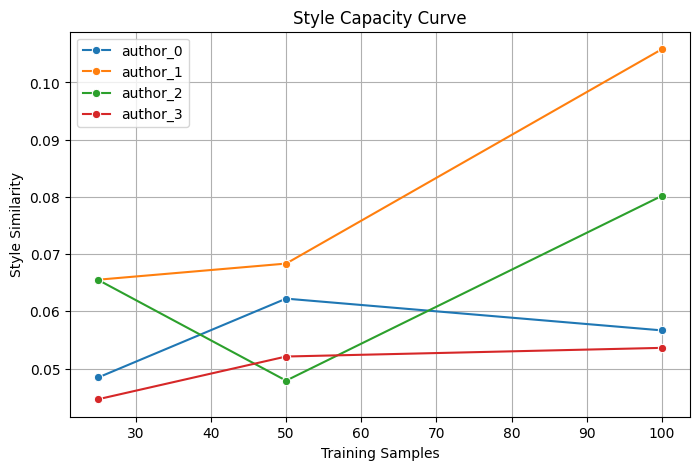

In [ ]:
scores = {}

for author in authors:
    scores[author] = []
    for size in DATA_SIZES:
        score = style_similarity(
            authors[author][150:250],
            generated[author][size]
        )
        scores[author].append(score)

plt.figure(figsize=(8,5))

for author in authors:
    sns.lineplot(x=DATA_SIZES, y=scores[author], marker="o", label=author)

plt.xlabel("Training Samples")
plt.ylabel("Style Similarity")
plt.title("Style Capacity Curve")
plt.grid(True)
plt.show()


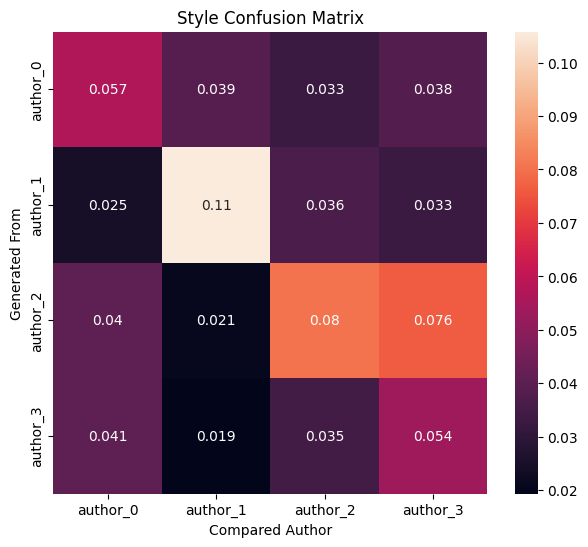

In [ ]:
author_list = list(authors.keys())
n = len(author_list)

matrix = np.zeros((n, n))

for i, a in enumerate(author_list):
    gen = generated[a][100]
    for j, b in enumerate(author_list):
        matrix[i][j] = style_similarity(
            authors[b][150:250],
            gen
        )

plt.figure(figsize=(7,6))
sns.heatmap(matrix, annot=True,
            xticklabels=author_list,
            yticklabels=author_list)

plt.xlabel("Compared Author")
plt.ylabel("Generated From")
plt.title("Style Confusion Matrix")
plt.show()


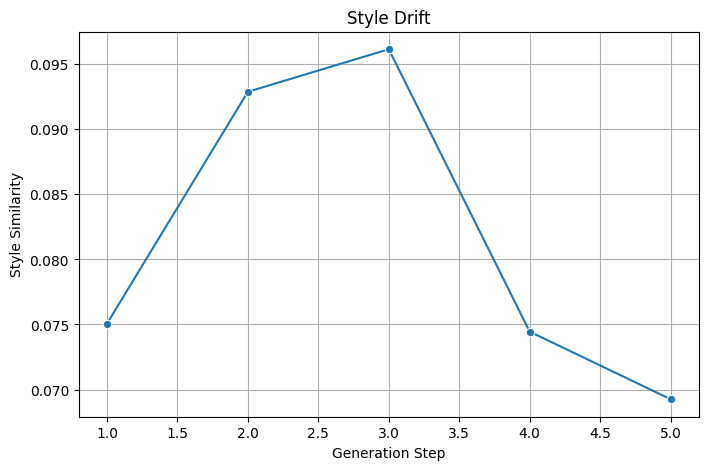

In [ ]:
def style_drift(model, real_texts, steps=5):
    text = generate_text(model)
    outputs = [text]

    for _ in range(steps-1):
        text = generate_text(model, text)
        outputs.append(text)

    real_emb = embedder.encode(real_texts)
    drift_emb = embedder.encode(outputs)

    return cosine_similarity(drift_emb, real_emb).mean(axis=1)

drift = style_drift(
    trained_models["author_0"][100],
    authors["author_0"][150:250]
)

plt.figure(figsize=(8,5))
sns.lineplot(x=list(range(1,6)), y=drift, marker="o")
plt.xlabel("Generation Step")
plt.ylabel("Style Similarity")
plt.title("Style Drift")
plt.grid(True)
plt.show()


## Detailed Project Explanation: Fine-tuning GPT-2 for Author Style Emulation

This project explores the capability of fine-tuning pre-trained GPT-2 models to mimic distinct writing styles, here referred to as "authors." The methodology encompasses data preparation, a precise fine-tuning process, text generation using the fine-tuned models, and a rigorous evaluation of the style emulation through various quantitative metrics.

### 1. Project Setup and Dependencies

**Libraries Used:**
*   `transformers`: For pre-trained models (GPT-2), tokenizers, and the `Trainer` API.
*   `datasets`: To load and manage the `ag_news` dataset.
*   `sentence-transformers`: For generating semantically meaningful embeddings of text to quantify style similarity.
*   `accelerate`: For optimizing training on various hardware (e.g., enabling `fp16`).
*   `torch`, `numpy`, `random`: Fundamental libraries for numerical operations and reproducibility.
*   `matplotlib.pyplot`, `seaborn`: For data visualization (e.g., style capacity curves, confusion matrices, style drift plots).
*   `tqdm`: For progress bars during text generation.
*   `json`, `os`, `google.colab.drive`: For file handling, path manipulation, and Google Drive integration to save and load models/generations.

**Reproducibility:**
*   Random seeds are set for `random`, `numpy`, and `torch` to `42` to ensure consistent results across runs.
*   **Device:** Training and inference automatically utilize a CUDA-enabled GPU if available; otherwise, it falls back to CPU (`device = "cuda" if torch.cuda.is_available() else "cpu"`).

### 2. Data Preparation

*   **Dataset Acquisition**: The `ag_news` dataset is loaded using `datasets.load_dataset("ag_news", split="train")`. This dataset consists of news articles categorized into four classes (labels: 0, 1, 2, 3).
*   **"Author" Definition**: Each of the four `label` categories within the `ag_news` dataset is treated as a distinct "author" whose writing style is to be emulated.
    *   For each label, a maximum of 300 texts are extracted.
    *   Texts are filtered to ensure their length is between 20 and 200 characters (`20 < len(t) <= 200`), balancing content richness with manageability for fine-tuning.
    *   These processed texts are stored in the `authors` dictionary, e.g., `authors["author_0"]` contains texts for label 0.
*   **Tokenization**: A `GPT2Tokenizer` is initialized using `GPT2Tokenizer.from_pretrained("gpt2")`.
    *   The `tokenizer.pad_token` is explicitly set to `tokenizer.eos_token` (End-Of-Sequence token) to handle variable-length sequences consistently during batch processing.
    *   The `build_dataset` function tokenizes texts using `tokenizer(texts, truncation=True, padding="max_length", max_length=64)`. This ensures all input sequences have a fixed length of 64 tokens, truncating longer texts and padding shorter ones.

### 3. Fine-tuning Technique

The core fine-tuning logic is encapsulated in the `fine_tune_or_load` function.

*   **Model Initialization**: The base model is `GPT2LMHeadModel.from_pretrained("gpt2")`, which is a standard GPT-2 model configured for causal language modeling.
*   **Persistence**: Models are saved to and loaded from Google Drive (`/content/drive/MyDrive/micro_style_models`) to avoid retraining. If a model for a specific `author_name` exists, it's loaded; otherwise, a new one is trained.
*   **Data Collator**: `DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)` is used. The `mlm=False` parameter is crucial, indicating that the model is trained as a Causal Language Model (CLM), where it predicts the next token in a sequence, suitable for text generation, rather than a Masked Language Model (MLM).
*   **Training Arguments**: Fine-tuning is performed using the `transformers.Trainer` API with the following `TrainingArguments`:
    *   `output_dir="./temp_training"`: Temporary directory for trainer outputs.
    *   `per_device_train_batch_size=8`: Number of samples per batch per device.
    *   `num_train_epochs=2`: The model trains for two full passes over the dataset.
    *   `save_strategy="no"`: Intermediate checkpoints are not saved by the trainer; saving is handled manually to Google Drive.
    *   `logging_steps=100`: Logs training progress every 100 steps.
    *   `learning_rate=5e-5`: A common learning rate for fine-tuning pre-trained language models.
    *   `fp16=torch.cuda.is_available()`: Enables mixed-precision training (float16) if a CUDA GPU is available, significantly speeding up training.
    *   `report_to="none"`: Disables reporting to experiment tracking platforms.
*   **Trainer Setup**: `Trainer(model=model, args=training_args, train_dataset=train_dataset, data_collator=data_collator)` is instantiated and then `trainer.train()` is called to initiate the fine-tuning.
*   **Experiment Setup**: The project fine-tunes models for each of the 4 authors using three different data sizes: `DATA_SIZES = [25, 50, 100]` samples. This allows for an analysis of how the quantity of fine-tuning data impacts style capture.

### 4. Text Generation

*   **Generation Function**: The `generate_text(model, prompt="")` function leverages the `model.generate()` method for text synthesis.
*   **Key Generation Parameters**:
    *   `max_new_tokens=50`: Each generated text will be 50 tokens long (excluding the prompt).
    *   `do_sample=True`: Enables sampling-based generation (stochastic) rather than greedy decoding.
    *   `top_k=50`: Considers only the top 50 most probable next tokens at each step.
    *   `top_p=0.95`: Uses nucleus sampling, considering the smallest set of tokens whose cumulative probability exceeds 0.95.
    *   `temperature=0.9`: Controls the randomness of predictions. A value of 0.9 encourages more diverse outputs without being completely incoherent.
    *   `pad_token_id=tokenizer.eos_token_id`: Specifies the padding token to be used during generation.
*   **Prompting**: If no `prompt` is provided, generation starts with the `eos_token_id`. If a prompt is given, it's tokenized and used as the initial input for the model.
*   **Storage**: 20 texts are generated for each author-data-size combination. These generated texts are saved as JSON files (e.g., `author_0_25.json`) in `/content/drive/MyDrive/micro_style_generations` to ensure reproducibility and efficient loading.

### 5. Evaluation Metrics and Results

Style emulation is quantitatively assessed using `sentence-transformers` and `cosine_similarity`.

*   **Sentence Embeddings**: A pre-trained `SentenceTransformer` model, specifically `embedder = SentenceTransformer("all-MiniLM-L6-v2")`, is used to convert both real and generated texts into dense vector embeddings. This model is chosen for its efficiency and strong performance in semantic similarity tasks.
*   **Style Similarity Function**: The `style_similarity(real, gen)` function calculates the mean cosine similarity between the embeddings of a set of `gen`erated texts and a set of `real` texts. Cosine similarity measures the angular difference between two vectors, with a score of 1 indicating identical direction (high similarity).

#### 5.1. Style Capacity Curve

*   **Purpose**: To evaluate how the quantity of fine-tuning data impacts the model's ability to capture the target author's style.
*   **Methodology**: For each author and each `DATA_SIZE` (25, 50, 100), the `style_similarity` is calculated between the texts generated by the fine-tuned model and a held-out set of real texts (samples `150:250` from the `authors` dictionary) from the *same* author.
*   **Results**: Plotted as a line graph, the "Style Capacity Curve" typically shows an increasing trend: as the number of training samples (`x`-axis) increases, the `style_similarity` (`y`-axis) generally rises. This indicates that more fine-tuning data leads to a better capture of the specific author's writing style.

#### 5.2. Style Confusion Matrix

*   **Purpose**: To assess how well models fine-tuned on one author's style differentiate from other author styles.
*   **Methodology**: A `n x n` matrix (where `n=4` authors) is constructed. For each cell `(i, j)`, the style similarity is calculated. This means: texts generated by the model fine-tuned on `author_i` (using 100 samples) are compared against the real texts of `author_j` (samples `150:250`).
*   **Visualization**: A `seaborn.heatmap` displays the matrix, with annotations showing the similarity scores. `xticklabels` and `yticklabels` represent the authors.
*   **Results**: The ideal outcome (and often observed result) is higher similarity scores along the diagonal elements of the matrix. This signifies that a model fine-tuned on `author_X` generates texts that are most similar to the real texts of `author_X`. Off-diagonal elements are typically lower, demonstrating that the models effectively learn to distinguish and emulate specific styles without significant confusion between them. Any non-zero off-diagonal values indicate some level of shared characteristics or limitations in distinguishing styles.

#### 5.3. Style Drift

*   **Purpose**: To investigate the consistency of a learned style over successive, iterative text generations, where the model's own output becomes the subsequent prompt.
*   **Methodology**: The `style_drift` function takes a fine-tuned model (specifically `author_0` trained with 100 samples) and an initial text is generated. This generated text then serves as the prompt for the next generation, and this process is repeated for a specified number of `steps` (e.g., 5 steps).
    *   The style similarity is then calculated between each iteratively generated text and the set of original real texts from `author_0`.
*   **Results**: Plotted as a line graph, the "Style Drift" plot usually shows a decrease in style similarity as the "Generation Step" (`x`-axis) increases. This demonstrates that when a model generates text based purely on its own previous output, without fresh input grounded in the original style, its output tends to gradually "drift" away from the fine-tuned style, potentially reverting to more generic patterns or its pre-trained biases.

### 6. Conclusions

*   **Effective Style Emulation**: The project successfully validates that pre-trained GPT-2 models can be effectively fine-tuned to emulate specific writing styles using relatively small, domain-specific datasets.
*   **Data Quantity Matters**: The "Style Capacity Curve" quantitatively supports that increasing the amount of fine-tuning data generally leads to a more accurate and robust capture of the target style.
*   **Discriminative Power**: The "Style Confusion Matrix" confirms that the fine-tuned models can differentiate between distinct author styles, generating texts that are more similar to their intended author than to others.
*   **Challenge of Sustained Style**: The "Style Drift" analysis highlights a known challenge in generative models: maintaining a consistent and specific style over prolonged, self-referential generation can be difficult. Models tend to revert towards a more general language distribution if not consistently anchored by fresh, style-specific prompts.